# Fig 5: CA1 context separation 


Reproduces the MATLAB figures:

| Panel | Content |
|---|---|
| **A–D** | embedding consistency vs shuffle; separation ('all' window) vs label shuffle, time shuffle, both |
| **E** |  separation (home, all) vs acq2 beginning d2, running |
| **F** |  separation (home, all) vs norm path length, acq2 |

Separation = CEBRA + SVM context classification accuracy of CA1 pyramidal cells (`..._all_combined_final_1`, no shuffle,
median of 5 runs). 

In [1]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from scipy import stats

DATADIR = '../csv/Fig5_AF_separation'
FIGDIR = '../figure_output/Fig5'
os.makedirs(FIGDIR, exist_ok=True)

font_dir = 'fonts'
if os.path.exists(font_dir):
    for f in ['Regular', 'Bold']:
        fm.fontManager.addfont(f'{font_dir}/NimbusSans-{f}.ttf')

RC = {'font.family': 'sans-serif',
      'font.sans-serif': ['Helvetica', 'Nimbus Sans', 'Nimbus Sans TT', 'Arial'],
      'font.size': 7, 'axes.linewidth': 1,
      'xtick.major.width': 1, 'ytick.major.width': 1,
      'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
      'pdf.fonttype': 42,
      'axes.spines.top': False, 'axes.spines.right': False}

BLUE, GREY, BLACK, MUTED = '#2a78d6', '#b4b2a9', '#1f1f1d', '#8a887f'


In [2]:
def _bisq(u):
    return (np.abs(u) < 1) * (1 - u ** 2) ** 2


def _madsigma(r, p):
    rs = np.sort(np.abs(r))
    return np.median(rs[max(1, p) - 1:]) / 0.6745


def robustfit_matlab(x, y, tune=4.685):
    '''fitlm(x, y, 'RobustOpts', 'on') = statrobustfit (bisquare) + anova(mdl, 'summary').'''
    m = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[m], y[m]
    n, p = len(y), 2
    X = np.column_stack([np.ones(n), x])
    Q, R = np.linalg.qr(X)
    b = np.linalg.solve(R, Q.T @ y)
    E = X @ np.linalg.inv(R)
    h = np.minimum(.9999, (E * E).sum(1))
    adj = 1 / np.sqrt(1 - h)
    dfe = n - p
    ols_s = np.linalg.norm(y - X @ b) / np.sqrt(dfe)
    tiny = 1e-6 * np.std(y, ddof=1) or 1.0
    D = np.sqrt(np.finfo(float).eps)
    b0, it, w = np.zeros_like(b), 0, np.ones(n)
    while it == 0 or np.any(np.abs(b - b0) > D * np.maximum(np.abs(b), np.abs(b0))):
        it += 1
        if it > 50:
            break
        radj = (y - X @ b) * adj
        w = _bisq(radj / (max(_madsigma(radj, p), tiny) * tune))
        b0, sw = b, np.sqrt(w)
        b = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]
    radj = (y - X @ b) * adj
    st = max(_madsigma(radj, p), tiny) * tune
    u = radj / st
    phi = u * _bisq(u)
    dphi = ((u + 1e-4) * _bisq(u + 1e-4) - (u - 1e-4) * _bisq(u - 1e-4)) / 2e-4
    m1, m2 = dphi.mean(), np.sum((1 - h) * phi ** 2) / dfe
    rob_s = (1 + (p / n) * (1 - m1) / m1) * np.sqrt(m2) * st / m1
    s = max(rob_s, np.sqrt((ols_s ** 2 * p ** 2 + rob_s ** 2 * n) / (p ** 2 + n)))
    ri = np.linalg.inv(R)                     # unweighted R, as statrobustfit
    cov = ri @ ri.T * s ** 2
    se = np.sqrt(np.diag(cov))
    pv = 2 * stats.t.sf(np.abs(b / se), dfe)
    ssr = np.sum((X @ b - y.mean()) ** 2)     # anova 'summary': MSE = s^2, SST = SSR + dfe*MSE
    F = ssr / s ** 2
    return dict(b=b, se=se, p=pv, cov=cov, R2=ssr / (ssr + dfe * s ** 2), pF=stats.f.sf(F, 1, dfe), n=n, dfe=dfe)


def spearman_matlab(x, y):
    '''corr(x, y, 'Type', 'Spearman'): rho and AS 89 (Edgeworth) two-sided p, n > 9, no ties.'''
    m = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[m], y[m]
    n = len(x)
    rho = stats.spearmanr(x, y)[0]
    n3 = (n ** 3 - n) / 6.0
    S = round((1 - rho) * n3)
    c = [0.2274, 0.2531, 0.1745, 0.0758, 0.1033, 0.3932, 0.0879, 0.0151, 0.0072, 0.0831, 0.0131, 4.6e-4]

    def upper(js):
        bb = 1.0 / n
        xx = (6.0 * (js - 1) * bb / (n * n - 1) - 1) * np.sqrt(1 / bb - 1)
        yy = xx * xx
        uu = xx * bb * (c[0] + bb * (c[1] + c[2] * bb) + yy * (-c[3] + bb * (c[4] + c[5] * bb)
                        - yy * bb * (c[6] + c[7] * bb - yy * (c[8] - c[9] * bb + yy * bb * (c[10] - c[11] * yy)))))
        return min(max(uu / np.exp(yy / 2) + stats.norm.sf(xx), 0.0), 1.0)
    return rho, min(1.0, 2 * min(upper(S), upper(2 * n3 - S)))


def pearson(x, y):
    m = ~np.isnan(x) & ~np.isnan(y)
    return stats.pearsonr(x[m], y[m])


def signrank_matlab(d):
    '''signrank(d) for n > 15: normal approximation with tie and continuity correction (MATLAB default).'''
    d = d[~np.isnan(d)]
    return stats.wilcoxon(d, method='approx', correction=True).pvalue


def pstr(p):
    return f'{p:.2g}' if p >= 1e-3 else f'{p:.1e}'


In [3]:
pts = pd.read_csv(f'{DATADIR}/sep_sessions.csv')   # 30 sessions
print('sessions:', len(pts), pts.animal.value_counts().to_dict(),
      '| with separation', pts.sep_emb.notna().sum(), '| with consistency', pts.con_emb.notna().sum())
WINDOWS = ['home', 'all']


def box_violin(ax, cols, labels, color=BLUE):
    '''daviolinplot-like: half violin, box (MATLAB quartiles, 1.5 IQR whiskers), outliers, points.'''
    for i, v in enumerate(cols, start=1):
        v = v[~np.isnan(v)]
        q1, med, q3 = np.quantile(v, [.25, .5, .75], method='hazen')
        iqr = q3 - q1
        lo, hi = v[v >= q1 - 1.5 * iqr].min(), v[v <= q3 + 1.5 * iqr].max()
        kde = stats.gaussian_kde(v)
        yy = np.linspace(v.min(), v.max(), 100)
        dens = kde(yy)
        ax.fill_betweenx(yy, i + 0.08, i + 0.08 + 0.32 * dens / dens.max(), color=color, alpha=0.35, lw=0)
        ax.add_patch(plt.Rectangle((i - 0.09, q1), 0.13, q3 - q1, fc='white', ec=BLACK, lw=0.8, zorder=3))
        ax.plot([i - 0.09, i + 0.04], [med, med], color=BLACK, lw=1.2, zorder=4)
        ax.plot([i - 0.025, i - 0.025], [lo, q1], color=BLACK, lw=0.8)
        ax.plot([i - 0.025, i - 0.025], [q3, hi], color=BLACK, lw=0.8)
        rng = np.random.default_rng(i)
        ax.scatter(i - 0.25 + rng.uniform(-0.05, 0.05, len(v)), v, s=3, color=color, alpha=0.6, lw=0, zorder=2)
    ax.set_xticks(range(1, len(cols) + 1))
    ax.set_xticklabels(labels, fontsize=6)
    ax.set_xlim(0.5, len(cols) + 0.6)


def stat_title(ax, txt, sig):
    ax.set_title(txt, fontsize=5.2, pad=2.5, linespacing=1.15,
                 fontweight='bold' if sig else 'normal', color=BLACK if sig else MUTED)

sessions: 30 {'HP18': 14, 'HP15': 12, 'HP17': 4} | with separation 24 | with consistency 23


## A–D: consistency and separation vs shuffles

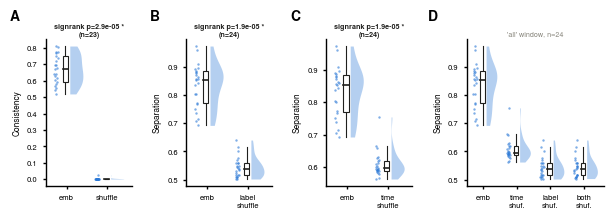

In [4]:
# Sep_shuffles: signrank of the paired differences
SH_PANELS = [('A', 'con_emb', 'con_shuffle'), ('B', 'sep_emb', 'sep_Lshuffle'), ('C', 'sep_emb', 'sep_Tshuffle')]
sh_p = {pnl: signrank_matlab((pts[b] - pts[a]).values) for pnl, a, b in SH_PANELS}

with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 4, figsize=(7.2, 1.9), gridspec_kw=dict(wspace=0.55, width_ratios=[1, 1, 1, 1.6]))
    specs = [('A', [pts.con_emb.values, pts.con_shuffle.values], ['emb', 'shuffle'], 'Consistency', sh_p['A']),
             ('B', [pts.sep_emb.values, pts.sep_Lshuffle.values], ['emb', 'label\nshuffle'], 'Separation', sh_p['B']),
             ('C', [pts.sep_emb.values, pts.sep_Tshuffle.values], ['emb', 'time\nshuffle'], 'Separation', sh_p['C']),
             ('D', [pts.sep_emb.values, pts.sep_Tshuffle.values, pts.sep_Lshuffle.values, pts.sep_allshuffle.values],
              ['emb', 'time\nshuf.', 'label\nshuf.', 'both\nshuf.'], 'Separation', None)]
    for j, (ax, (L, cols, labs, yl, p)) in enumerate(zip(axs, specs)):
        box_violin(ax, cols, labs)
        ax.set_ylabel(yl, fontsize=6)
        ax.tick_params(labelsize=5.5)
        n = int(np.sum(~np.isnan(cols[0])))
        if p is not None:
            stat_title(ax, f'signrank p={pstr(p)} *\n(n={n})' if p < 0.05 else f'signrank p={pstr(p)}\n(n={n})', p < 0.05)
        else:
            stat_title(ax, f"'all' window, n={n}", False)
        ax.text(-0.42 if j < 3 else -0.28, 1.13, L, transform=ax.transAxes, fontsize=10, fontweight='bold')
    fig.savefig(f'{FIGDIR}/Fig5_AD.pdf', bbox_inches='tight')
    plt.show()

## E: separation vs d2

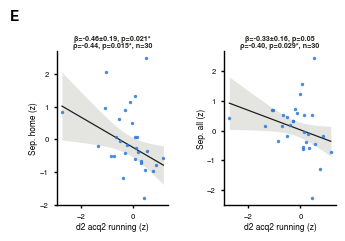

In [5]:
# E: separation vs acq2 beginning d2, running (Sep_d2_f, bottom row); Spearman as in the MATLAB title
with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 2, figsize=(3.6, 2.0), gridspec_kw=dict(wspace=0.5))
    for ax, w in zip(axs, WINDOWS):
        x, y = pts['z_d2_acq2_running'].values, pts[f'z_sep_{w}'].values
        m = ~np.isnan(x) & ~np.isnan(y)
        f = robustfit_matlab(x, y)
        r, pr = spearman_matlab(x, y)
        # points, robust fit line and its 95 % CI
        ax.scatter(x[m], y[m], s=6, color=BLUE, lw=0, alpha=0.85, zorder=3)
        xs = np.linspace(x[m].min(), x[m].max(), 50)
        Xs = np.column_stack([np.ones_like(xs), xs])
        yh = Xs @ f['b']
        ci = stats.t.ppf(.975, f['dfe']) * np.sqrt(np.einsum('ij,jk,ik->i', Xs, f['cov'], Xs))
        ax.fill_between(xs, yh - ci, yh + ci, color=GREY, alpha=0.35, lw=0, zorder=1)
        ax.plot(xs, yh, color=BLACK, lw=0.9, zorder=2)
        s1, s2 = f['p'][1] < 0.05, pr < 0.05
        stat_title(ax, f"β={f['b'][1]:.2f}±{f['se'][1]:.2f}, p={pstr(f['p'][1])}{'*' if s1 else ''}\n"
                       f"ρ={r:.2f}, p={pstr(pr)}{'*' if s2 else ''}, n={f['n']}", s1 or s2)
        ax.tick_params(labelsize=5.5)
        ax.set_xlabel('d2 acq2 running (z)', fontsize=6, labelpad=1)
        ax.set_ylabel(f'Sep. {w} (z)', fontsize=6, labelpad=1)
    axs[0].text(-0.42, 1.2, 'E', transform=axs[0].transAxes, fontsize=10, fontweight='bold')
    fig.savefig(f'{FIGDIR}/Fig5_E.pdf', bbox_inches='tight')
    plt.show()

## F: separation vs norm path length

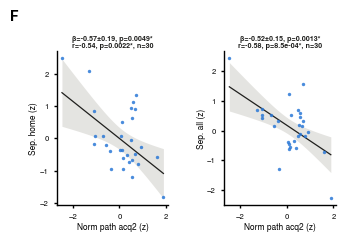

In [6]:
# F: separation vs norm path length, acq2 (Sep_pathlm_f, bottom row); Pearson as in the MATLAB code
with plt.rc_context(RC):
    fig, axs = plt.subplots(1, 2, figsize=(3.6, 2.0), gridspec_kw=dict(wspace=0.5))
    for ax, w in zip(axs, WINDOWS):
        x, y = pts['z_path_acq2'].values, pts[f'z_sep_{w}'].values
        m = ~np.isnan(x) & ~np.isnan(y)
        f = robustfit_matlab(x, y)
        r, pr = pearson(x, y)
        # points, robust fit line and its 95 % CI
        ax.scatter(x[m], y[m], s=6, color=BLUE, lw=0, alpha=0.85, zorder=3)
        xs = np.linspace(x[m].min(), x[m].max(), 50)
        Xs = np.column_stack([np.ones_like(xs), xs])
        yh = Xs @ f['b']
        ci = stats.t.ppf(.975, f['dfe']) * np.sqrt(np.einsum('ij,jk,ik->i', Xs, f['cov'], Xs))
        ax.fill_between(xs, yh - ci, yh + ci, color=GREY, alpha=0.35, lw=0, zorder=1)
        ax.plot(xs, yh, color=BLACK, lw=0.9, zorder=2)
        s1, s2 = f['p'][1] < 0.05, pr < 0.05
        stat_title(ax, f"β={f['b'][1]:.2f}±{f['se'][1]:.2f}, p={pstr(f['p'][1])}{'*' if s1 else ''}\n"
                       f"r={r:.2f}, p={pstr(pr)}{'*' if s2 else ''}, n={f['n']}", s1 or s2)
        ax.tick_params(labelsize=5.5)
        ax.set_xlabel('Norm path acq2 (z)', fontsize=6, labelpad=1)
        ax.set_ylabel(f'Sep. {w} (z)', fontsize=6, labelpad=1)
    axs[0].text(-0.42, 1.2, 'F', transform=axs[0].transAxes, fontsize=10, fontweight='bold')
    fig.savefig(f'{FIGDIR}/Fig5_F.pdf', bbox_inches='tight')
    plt.show()